Expérience 2

Partie I : Solution numérique du système

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#taille de la police des graphiques
plt.rc('font', size=12)          # Taille de base par défaut
plt.rc('axes', titlesize=18)     # Taille du titre des axes
plt.rc('axes', labelsize=14)     # Taille des étiquettes des axes
plt.rc('xtick', labelsize=12)    # Taille des graduations de l'axe X
plt.rc('ytick', labelsize=12)    # Taille des graduations de l'axe Y
plt.rc('legend', fontsize=12)    # Taille de la légende

#changer la famille de police 
plt.rcParams['font.family'] = 'sans-serif'

#choix de police
plt.rcParams['font.sans-serif'] = ['Arial']

In [3]:
#Valeurs des conditions initiales
dt = 0.0001        #pas de temps


#définition de la fonction du système de lorenz

def lorenz(sigma, rho, beta, N, dt):    #N est le nombre de pas de temps
    eta = np.sqrt(beta * (rho -1))

    #aide de l'IA pour trouver la logique de création des tableaux
    x = np.zeros(N+1)
    y = np.zeros(N+1)
    z = np.zeros(N+1)    #création de 3 tableaux x y z rempli de 0 qui contiennent N+1 valeurs

    #conditions initiales
    x[0] = eta             #température
    y[0] = eta + 3         #humidité
    z[0] = rho - 1       #pression

    for n in range(N):                       #schéma d'Euler à la manière d'une suite
        x[n+1]= (sigma*(y[n] - x[n]))*dt + x[n]
        y[n+1]= (x[n]*(rho - z[n]) - y[n])*dt + y[n]
        z[n+1]= (x[n]*y[n] - beta*z[n])*dt + z[n]
        
    return x, y, z


In [4]:
#on appelle la fonction avec les paramètres de la question 1 :

lorenz(10, 10, 2.667, 20000, dt)

(array([4.89928566, 4.90228566, 4.90528236, ..., 5.15544992, 5.15585577,
        5.1562615 ], shape=(20001,)),
 array([7.89928566, 7.89898566, 7.89868527, ..., 5.56129934, 5.56158017,
        5.5618607 ], shape=(20001,)),
 array([9.        , 9.00146979, 9.0029414 , ..., 8.37656442, 8.37719749,
        8.37783076], shape=(20001,)))

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def tracer_graphique1(sigma, rho, beta, N, dt=0.0001):

    t = np.arange(N + 1) * dt
    x, y, z = lorenz(sigma, rho, beta, N, dt)

    fig = plt.figure(figsize=(10, 7))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1])   #pour avoir un graphique en haut et deux graphiques en bas, aider de l'IA

    #panneau 1 : graphique des 3 variables
    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(t, x, label="Température")
    ax1.plot(t, y, label="Humidité")
    ax1.plot(t, z, label="Pression")
    ax1.set_xlabel("Temps")
    ax1.set_ylabel("Variables de l'atmosphère")
    ax1.set_title("Évolution des variables de l'atmosphère dans le temps")
    ax1.legend()
    ax1.grid(True)

    #panneau 2 : ligne à gauche y(x)
    ax2 = fig.add_subplot(gs[1, 0])
    ax2.plot(y, x, color="blue")
    ax2.set_title("Température en fonction de l'humidité")
    ax2.set_xlabel("Humidité")
    ax2.set_ylabel("Température")

    #panneau 3 : ligne à droite z(x)
    ax3 = fig.add_subplot(gs[1, 1])
    ax3.plot(z, x, color="red")
    ax3.set_title("Température en fonction de la pression")
    ax3.set_xlabel("Pression")
    ax3.set_ylabel("Température")

    plt.tight_layout()
    plt.savefig("Graphique1")
    plt.show()

Partie 1.1 : La solution stationnaire

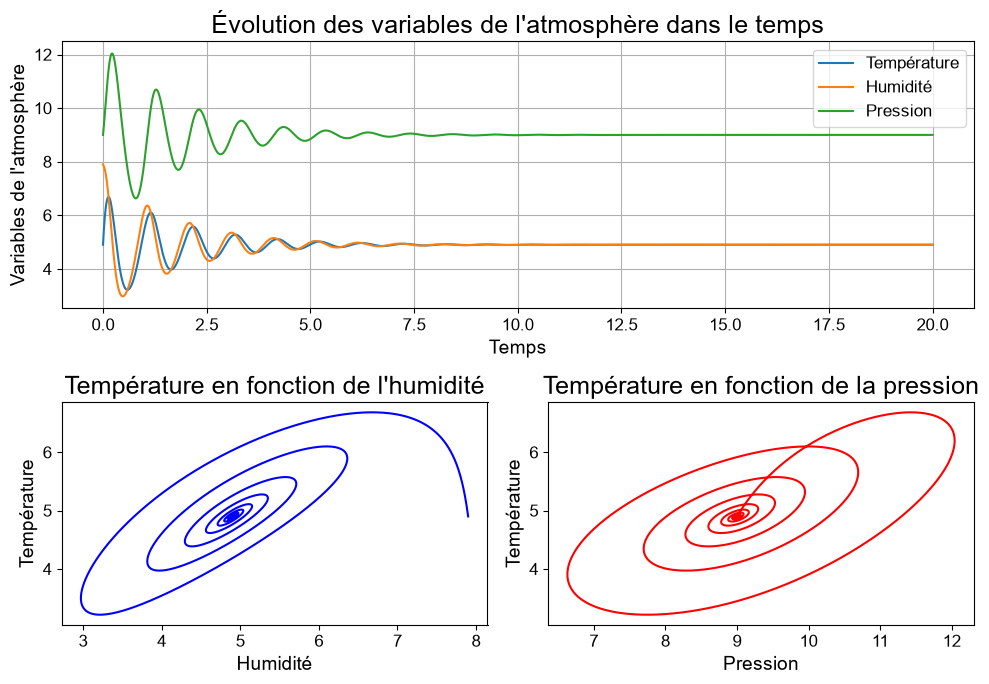

In [6]:
#1er graphique partie 1.1 
#appel de la fonction avec les paramètres de sigma, rho, beta et le nombre de pas de temps
tracer_graphique1(10, 10, 2.667, 20000, dt=0.001)

Partie 1.2 : La solution chaotique

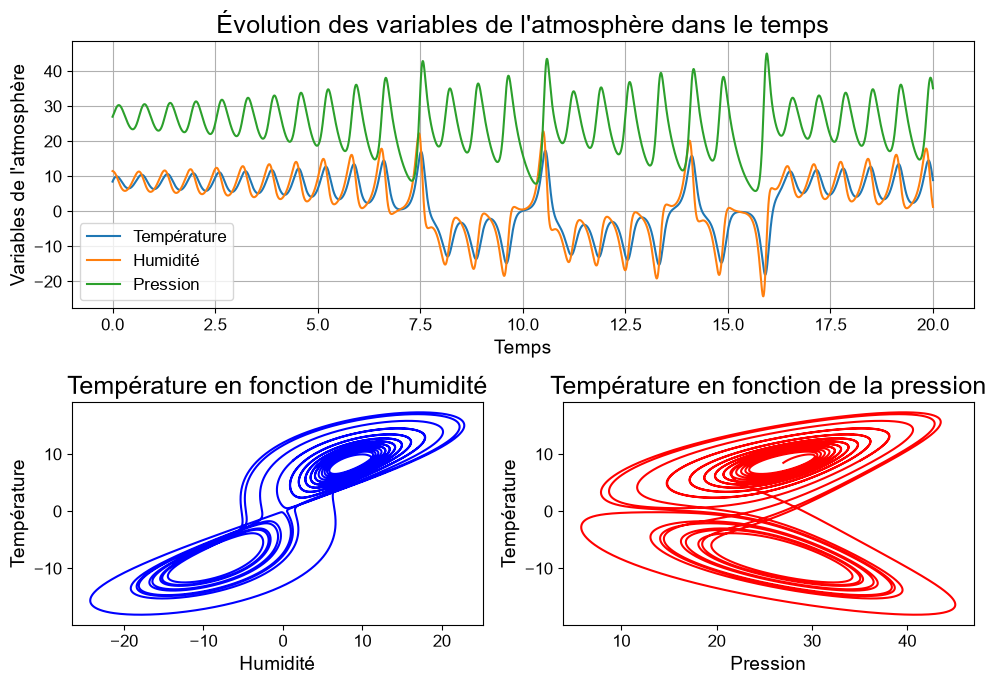

In [7]:
tracer_graphique1(10, 28, 2.667, 20000, dt=0.001)

Partie 1.3 : La solution périodique

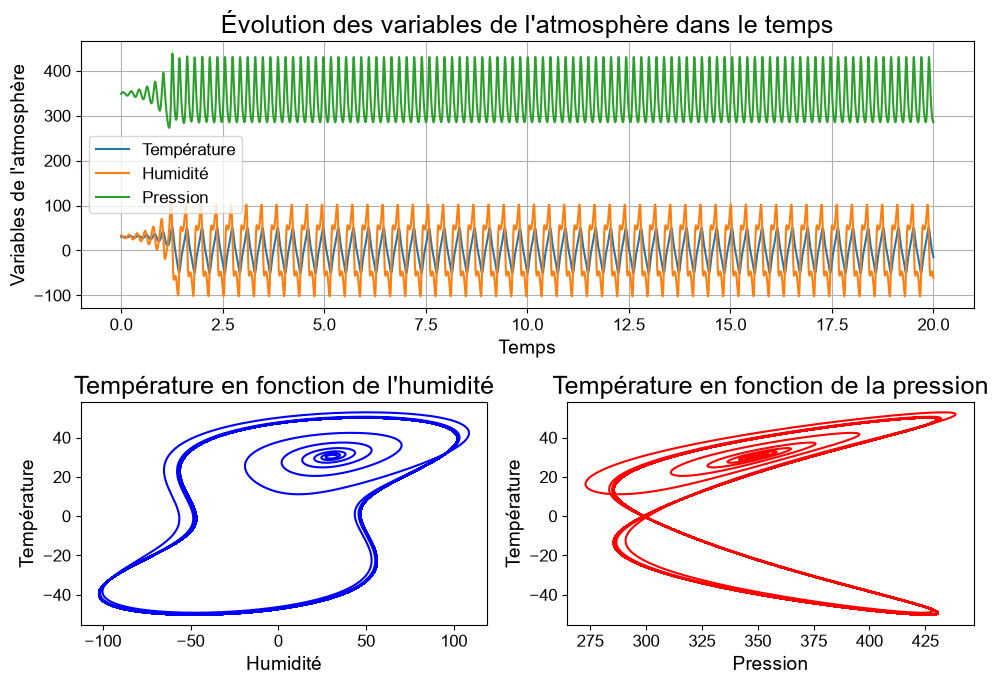

In [8]:
tracer_graphique1(10, 350, 2.667, 20000, dt=0.001)

Partie II : La prévisibilité du système chaotique 

2.1 Prévisibilité moyenne

In [9]:
#définition de la fonction du système de lorenz CONTRÔLÉE
#cette fois, on reprend la fonction du début en appliquant les conditions initiales

def lorenz2(sigma, rho, beta, N, dt, x0, y0, z0):  #les conditions initiales deviennent des variables de la fonction qu'on peut modifier
    eta = np.sqrt(beta * (rho -1))

    x = np.zeros(N+1)
    y = np.zeros(N+1)
    z = np.zeros(N+1)    #création de 3 tableaux x y z rempli de 0 qui contiennent N+1 valeurs

    
    x[0] = x0      #température
    y[0] = y0      #humidité
    z[0] = z0      #pression

    for n in range(N):                       #schéma d'Euler à la manière d'une suite
        x[n+1]= (sigma*(y[n] - x[n]))*dt + x[n]
        y[n+1]= (x[n]*(rho - z[n]) - y[n])*dt + y[n]
        z[n+1]= (x[n]*y[n] - beta*z[n])*dt + z[n]
        
    return x, y, z

In [10]:

#définition de la fonction pour tracer l'évolutions des CI contrôlées vs perturbées

def tracer_graphique21(sigma, rho, beta, N=2*10**4, dt=0.001, x0=8.9, y0=1.3, z0=35.1, epsilonx = 0.01):

    t = np.arange(N + 1) * dt   

    #variables x(t), y(t) et z(t) contrôlée
    x01, y01, z01 = lorenz2(sigma, rho, beta, N, dt, x0, y0, z0)

    #variables x(t), y(t) et z(t) contrôlée
    x02, y02, z02 = lorenz2(sigma, rho, beta, N, dt, x0 + epsilonx, y0, z0)


    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15))


    # Température en fonction du temps x(t)
    ax1.plot(t, x01, label="CI contrôlées")
    ax1.plot(t, x02, label="CI perturbées")
    ax1.set_xlabel("Temps (s)")
    ax1.set_ylabel("Température x(t)")
    ax1.set_title("Différence entre les deux solutions de l'évolution de la température dans le temps")
    ax1.legend()
    ax1.grid(True)

    # Humidité en fonction du temps y(t)
    ax2.plot(t, y01, label="CI contrôlées")
    ax2.plot(t, y02, label="CI perturbées")
    ax2.set_xlabel("Temps (s)")
    ax2.set_ylabel("Humidité y(t)")
    ax2.set_title("Différence entre les deux solutions de l'évolution de l'humidité dans le temps")
    ax2.legend()
    ax2.grid(True)

    # Pression en fonction du temps z(t)
    ax3.plot(t, z01, label="CI contrôlées")
    ax3.plot(t, z02, label="CI perturbées")
    ax3.set_xlabel("Temps (s)")
    ax3.set_ylabel("Pression z(t)")
    ax3.set_title("Différence entre les deux solutions de l'évolution de la pression dans le temps")
    ax3.legend()
    ax3.grid(True)

    plt.tight_layout()
    plt.savefig("Graphique2-1.png", dpi=300)
    plt.show()

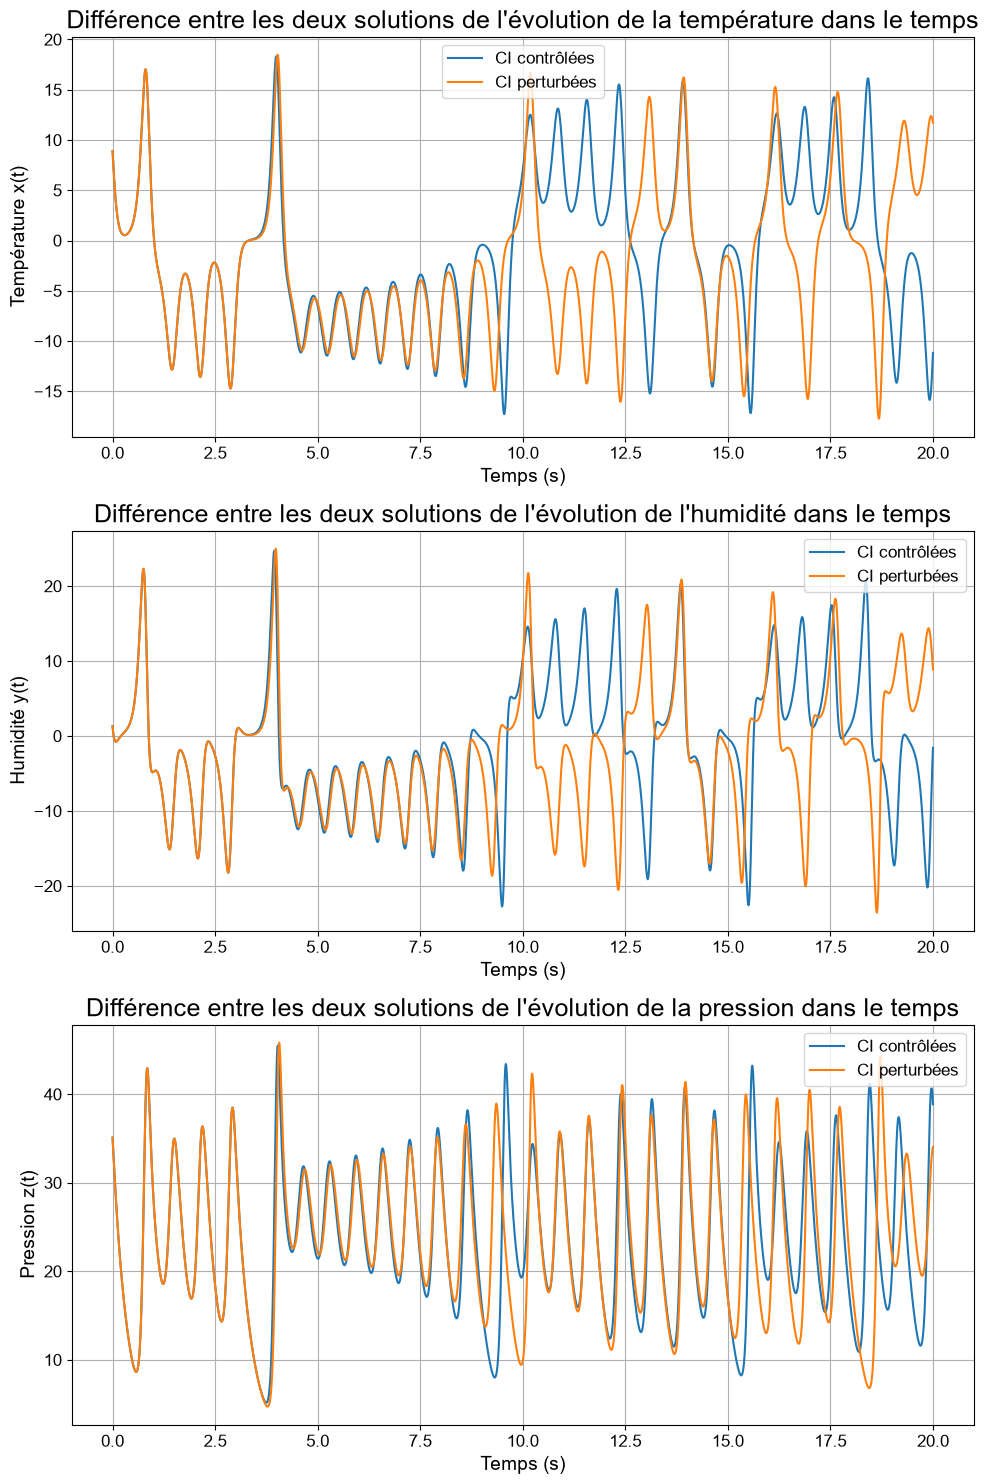

In [11]:
#qppel de la fonction avec les paramètres 
tracer_graphique21(10, 28.0, 2.667, N = 2*10**4, dt = 0.001)

In [12]:
#Calcul de l'écart type : l'écart tye est la racine carrée de la variance. 
#Il correspond à la dispersion des données autour de la moyenne

x01, y01, z01 = lorenz2(10, 28, 2.667, N=4*10**4, dt=0.001, x0=8.9, y0=1.3, z0=35.1)
x02, y02, z02 = lorenz2(10, 28, 2.667, N=4*10**4, dt=0.001, x0=8.91, y0=1.3, z0=35.1)

sigma_x = np.std(x01)   #fonction standard deviation (=ecart type)
sigma_y = np.std(y01)
sigma_z = np.std(z01)

print("L'écart-type de x(t) est ", sigma_x)
print("L'écart-type de y(t) est ", sigma_y)
print("L'écart-type de z(t) est ", sigma_z)

L'écart-type de x(t) est  7.840088091969276
L'écart-type de y(t) est  8.940875196870392
L'écart-type de z(t) est  8.600825887063888


In [13]:
#calcul de la différence absolue entre la solution de cntrôle et la solution perturbée

ecart_x = np.abs(x02 - x01)
dt=0.001
N=4*10**4
t = np.arange(N + 1) * dt 

#aide de l'IA pour trouver le raisonnement de la boucle

indices = np.where(ecart_x>sigma_x)[0]

if len(indices) > 0 :         #si le nombre d'indices est plus grand que 0
    indice_prev = indices[0]  #indice prev prend la valeur du premier indice où la différence absolue est plus grande que l'écart type 
    t_prev = t[indice_prev]   #récupère la valeur du temps associé à au premier indice, qui caractérise la prévisibilité de la solution
    
    print("Le temps de la prévisibilité est de :", t_prev)
else:
    print("Le seuil n'est pas atteint pendant la simulation.")  #si le seuil de prévisibilité n'est pas atteint

Le temps de la prévisibilité est de : 9.183


2.2 Exposant de Lyapunov

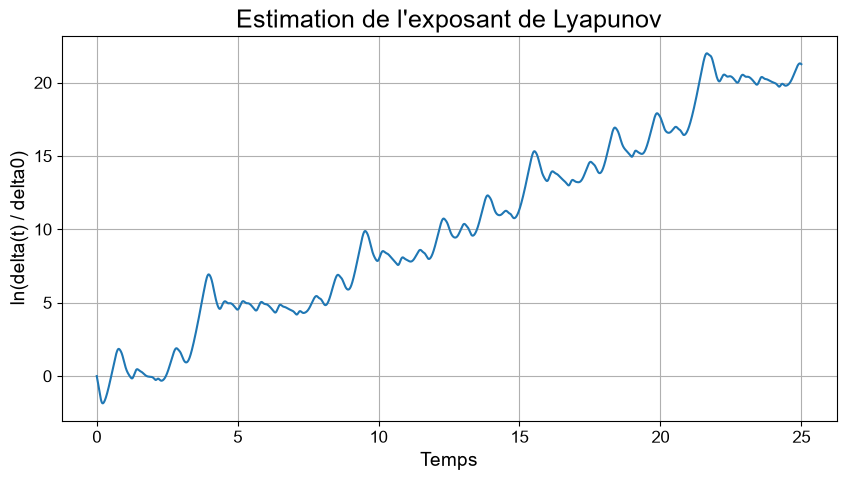

In [14]:
#solution contrôlée
xc, yc, zc = lorenz2(10, 28, 2.667, N=25000, dt=0.001, x0=8.9, y0=1.3, z0=35.1)

#solution perturbée
xp, yp, zp = lorenz2(10, 28, 2.667, N=25000, dt=0.001, x0=8.9+10**-8, y0=1.3, z0=35.1)

delta = np.sqrt((xp-xc)**2 + (yp-yc)**2 + (zp-zc)**2)   #distance entre solution contrôlée et perturbée à chaque pas de temps

#temps
N= 25000
t = np.arange(N + 1) * dt

# erreur initiale suffisament petite à t=0 delta0
delta0 = delta[0]

# définition de ln(delta(t)/delta(0)))
log_delta = np.log(delta / delta0)

# graphique seul à tracer pour déterminer a pente de lyapunov
plt.figure(figsize=(10, 5))
plt.plot(t, log_delta)
plt.xlabel("Temps")
plt.ylabel("ln(delta(t) / delta0)")
plt.title("Estimation de l'exposant de Lyapunov")
plt.grid(True)
plt.show()

#premier graphique qui sert à la lecture des temps pour lesquels l'exposant de Lyapunov est valable

In [15]:
#identification de l'ordonnée max et min par lecture graphique, et utilisation d'un masque pour les convertir en indice 
#aide de l'IA pour le masque et fonction polyfit
masque = (t >= 8) & (t <= 20)

#fonction polyfit pour tracer la droite tendance : la pente est l'exposant de Lyapunov, 1 pour fonction de degré 1(linéaire)
pente, ordonnee = np.polyfit(t[masque],log_delta[masque],1)

lyapunov = pente
print("Exposant de Lyupanov", lyapunov)
Td = np.log(2) / lyapunov
print("Le temps de doublement de l'erreur est : ", f"{Td:.2f}")

Exposant de Lyupanov 0.9042552129564504
Le temps de doublement de l'erreur est :  0.77


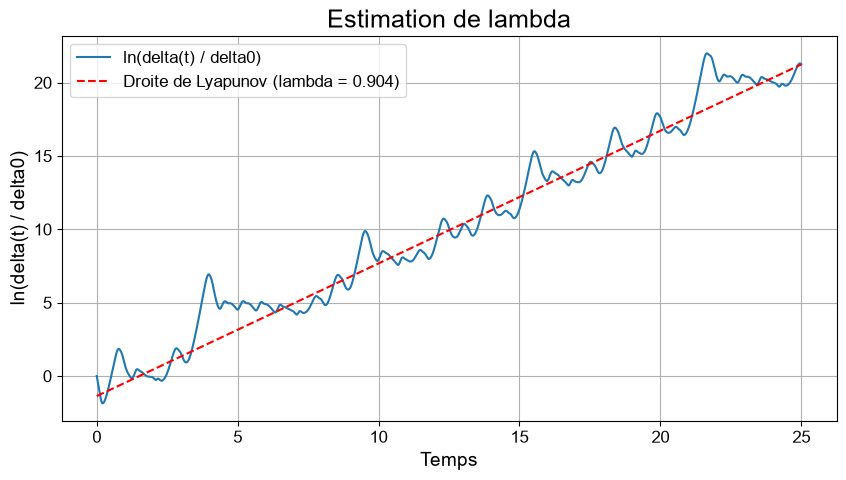

In [16]:

# Graphique de la courbe et de la droite de Lyapunov
plt.figure(figsize=(10, 5))

plt.plot(t, log_delta, label="ln(delta(t) / delta0)")

# Droite de Lyapunov
plt.plot( t, pente * t + ordonnee, "--", color="red", label=f"Droite de Lyapunov (lambda = {pente:.3f})")

plt.xlabel("Temps")
plt.ylabel("ln(delta(t) / delta0)")
plt.title("Estimation de lambda")
plt.legend()
plt.grid(True)
plt.savefig("Lyupanov2-2")  
plt.show()




2.3  Prévisibilité selon l’incertitude observationnelle

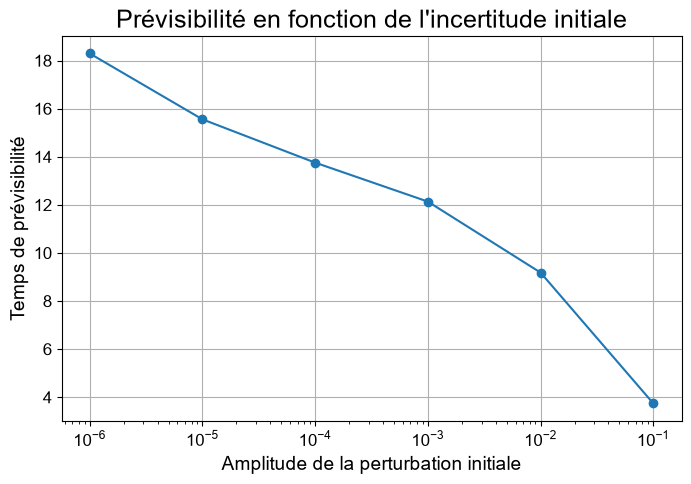

In [17]:
#calcul de la prévibilité pour différentes perturbations 
epsilons = [1e-6, 1e-5, 1e-4,1e-3, 1e-2, 1e-1]

xc, yc, zc = lorenz2(10, 28, 2.667, N=25000, dt=0.001, x0=8.9, y0=1.3, z0=35.1)

t = np.arange(N+1) *dt
sigma_x = np.std(xc)


#temps prévu en fonction de la magnitude de la perturbation (e-6, e-5,...)
temps_prev =[]  

#boucle pour rentrer chaque perturbation
for epsilon in epsilons:
    xp, yp, zp = lorenz2(10, 28, 2.667, N=25000, dt=0.001, x0=8.9 +epsilon, y0=1.3, z0=35.1)

    ecart_x = np.abs(xp-xc)

    indices = np.where(ecart_x>sigma_x)[0]
    
    if len(indices)> 0:
        temps_prev.append(t[indices[0]]) #ajoute l'indice du premier dépassement de seuil au tableau du temps de prévisibilité
    else:
        temps_prev.append(np.nan) #si le seuil n'est pas atteint, ajoute NaN au tableau

#graphique prévisibilité
plt.figure(figsize=(8, 5))
plt.plot(epsilons, temps_prev, "o-")
plt.xscale("log")  #axe logarithmique
plt.xlabel("Amplitude de la perturbation initiale")
plt.ylabel("Temps de prévisibilité")
plt.title("Prévisibilité en fonction de l'incertitude initiale")
plt.grid(True)
plt.savefig("Graphique2-3")
plt.show()

2.4 Prévisibilité selon le régime de temps

In [18]:
#conditions initiales 
conditions = {
    "A": [-11.5, -6.0, 36.1],
    "B": [-3.0, -4.8, 19.1],
    "C": [3.2, 4.2, 18.0],
    "D": [2.1, 3.0, 16.1],
    "E": [4.6, 6.9, 23.2],
    "F": [0.1, 7.1, 29.6]}

epsilon = 0.01
N = 25000
dt = 0.001
t=np.arange(N+1) * dt

temps_prev = {}   #on utilise un dictionnaire plutôt qu'une liste comme les CI sont nommées par des lettres

#pour chaque lettre, les conditions initiales prennent les valeurs x,y,z du tableau associé
for lettre, ci in conditions.items():
    x0,y0,z0 = ci

    #solution contrôlée
    xc, yc, zc = lorenz2(10, 28, 2.667, N, dt, x0, y0, z0)

    #solution pertubée
    xp, yp, zp = lorenz2(10, 28, 2.667, N, dt, x0 + epsilon, y0, z0) 

    sigma_x = np.std(xc)
    ecart_x = np.abs(xp-xc)
    indices = np.where(ecart_x > sigma_x)[0]

    if len(indices) > 0:
        temps_prev[lettre] = t[indices[0]]
    else:
        temps_prev[lettre] = np.nan

#afficher les temps de prévisibilité pour chaque conditions initiales
for lettre, temps in temps_prev.items():
    print("conditions initiales", lettre, "- temps de prévisibilité :", f"{temps:.6f}")


conditions initiales A - temps de prévisibilité : 1.828000
conditions initiales B - temps de prévisibilité : 2.169000
conditions initiales C - temps de prévisibilité : 4.283000
conditions initiales D - temps de prévisibilité : 7.058000
conditions initiales E - temps de prévisibilité : 8.840000
conditions initiales F - temps de prévisibilité : 9.619000


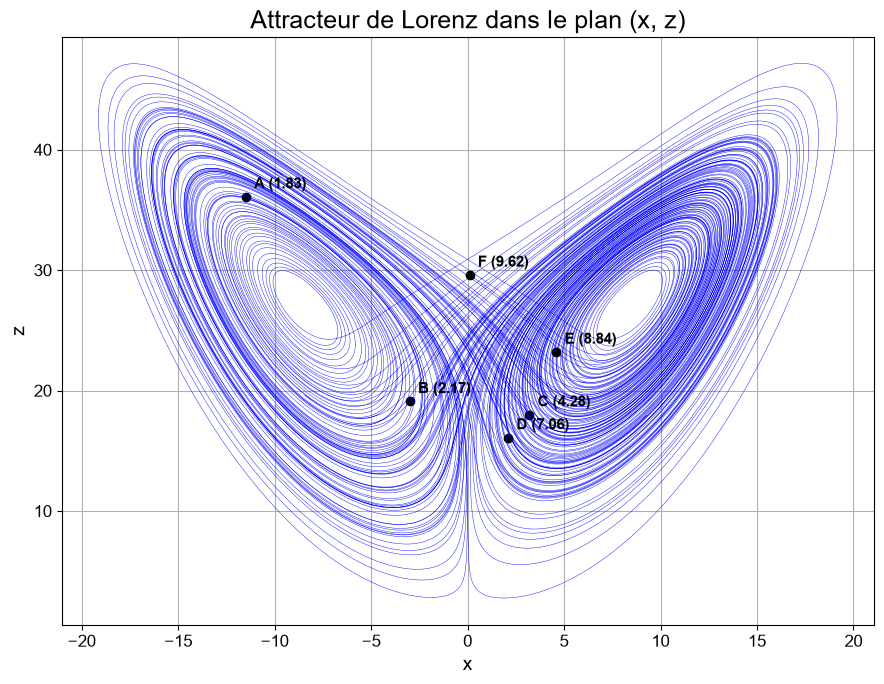

In [19]:
#figure de l'attracteur avec les 6 conditions initiales
plt.figure(figsize=(9, 7))

for lettre, ci in conditions.items():

    x0, y0, z0 = ci

    xc, yc, zc = lorenz2(10, 28, 2.667, N, dt, x0, y0, z0)

    # trajectoire
    plt.plot(xc, zc, color="blue", linewidth=0.3)

    # point de départ de la condition initiale
    plt.plot(x0, z0,"ko", markersize=6)
    plt.annotate(f"{lettre} ({temps_prev[lettre]:.2f})", (x0, z0), textcoords="offset points", xytext=(6, 6), fontsize=11, fontweight="bold")
plt.xlabel("x")
plt.ylabel("z")
plt.title("Attracteur de Lorenz dans le plan (x, z)")
plt.grid(True)
plt.tight_layout()
plt.savefig("Graphique2-4")
plt.show()

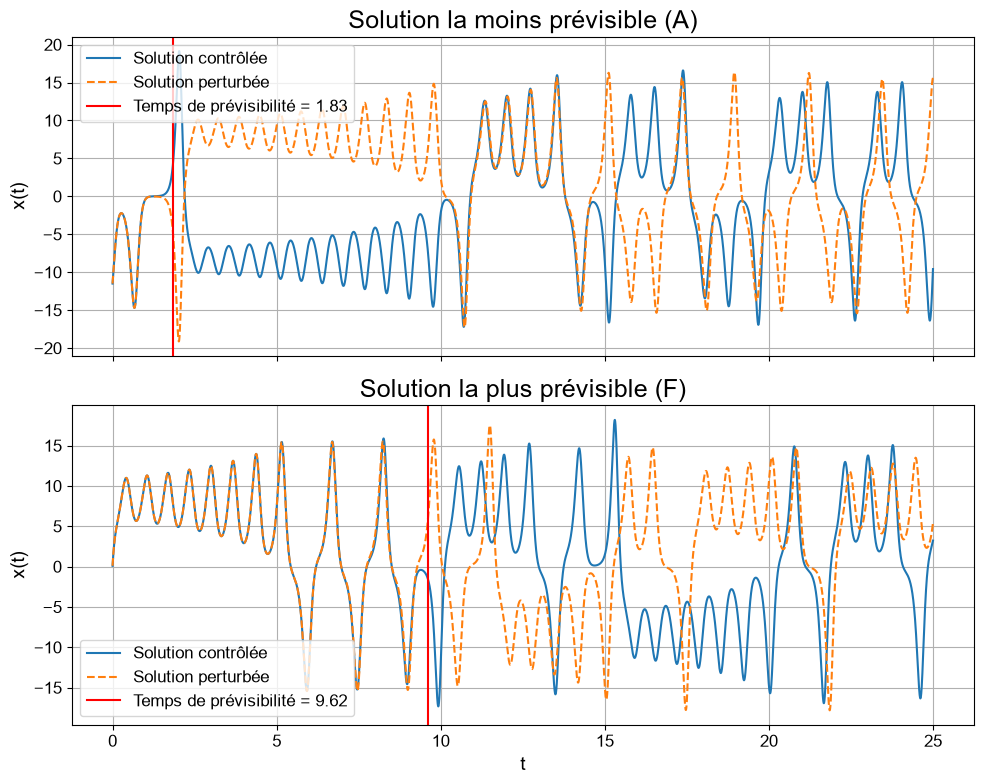

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# solution avec la plus petite prévisibilité (A)
xc_A, yc_A, zc_A = lorenz2(10, 28, 2.667, N, dt, *conditions["A"])
xp_A, yp_A, zp_A = lorenz2(10, 28, 2.667, N, dt, conditions["A"][0] + epsilon, conditions["A"][1], conditions["A"][2])

ax1.plot(t, xc_A, label="Solution contrôlée")
ax1.plot(t, xp_A, "--", label="Solution perturbée")
ax1.axvline(temps_prev["A"], color="red", label=f"Temps de prévisibilité = {temps_prev['A']:.2f}")
ax1.set_ylabel("x(t)")
ax1.set_title("Solution la moins prévisible (A)")
ax1.legend()
ax1.grid(True)

#solution avec la plus grande prévisibilité (F)

xc_F, yc_F, zc_F = lorenz2(10, 28, 2.667, N, dt, *conditions["F"])
xp_F, yp_F, zp_F = lorenz2(10, 28, 2.667, N, dt, conditions["F"][0] + epsilon, conditions["F"][1], conditions["F"][2])

ax2.plot(t, xc_F, label="Solution contrôlée")
ax2.plot(t, xp_F, "--", label="Solution perturbée")
ax2.axvline(temps_prev["F"], color="red", label=f"Temps de prévisibilité = {temps_prev['F']:.2f}")
ax2.set_xlabel("t")
ax2.set_ylabel("x(t)")
ax2.set_title("Solution la plus prévisible (F)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig("Graphique2-5.png")
plt.show()

Partie III : le climat dans le système chaotique

In [21]:
N = 10**5
epsilon = 0.01

#solution contrôlée
xc, yc, zc = lorenz2(10, 28, 2.667, N, dt, x0, y0, z0)
#solution perturbée
xp, yp, zp = lorenz2(10, 28, 2.667, N, dt, x0+epsilon, y0, z0)

controlee = {"x": xc, "y": yc, "z": zc}
perturbee = {"x": xp, "y": yp, "z": zp}

3.1 : Exploitation visuelle des différences

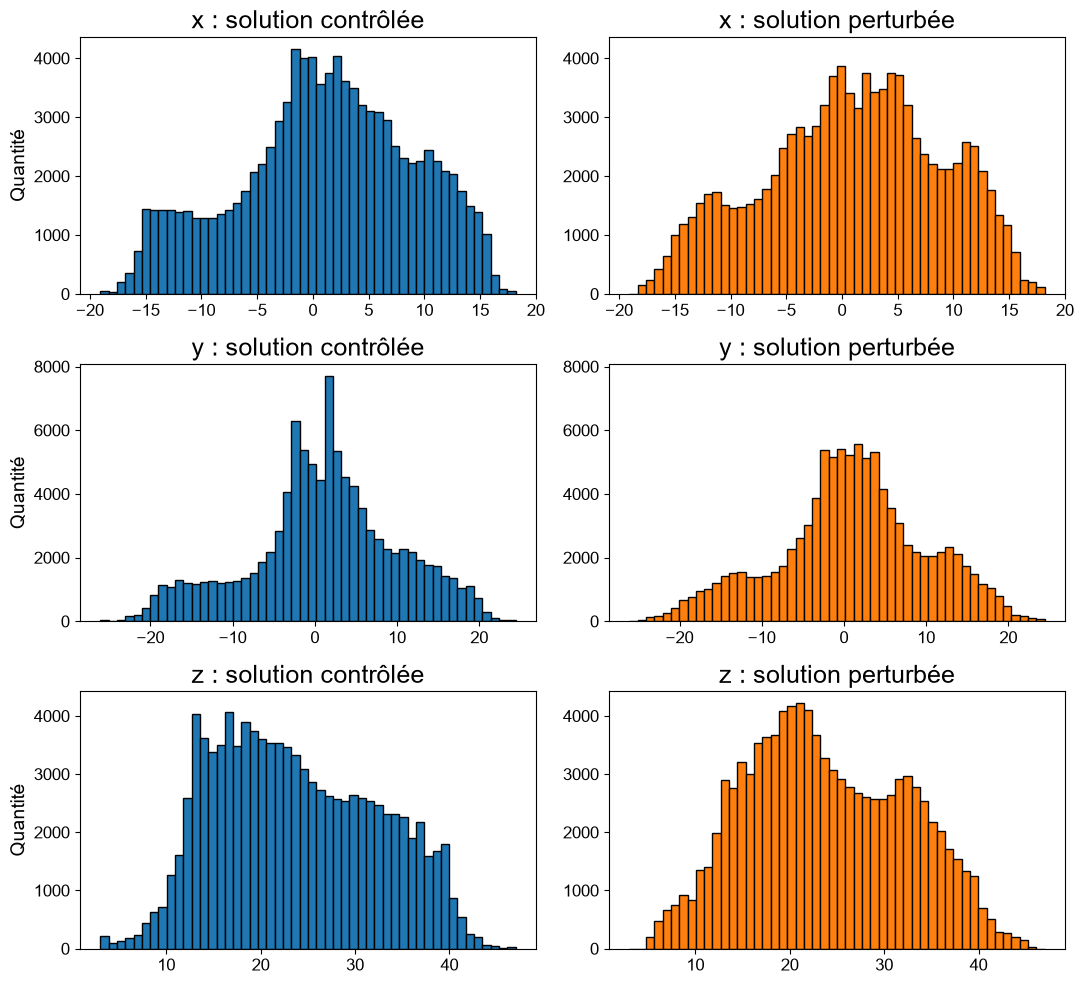

In [22]:
fig, axes = plt.subplots(3, 2, figsize=(11, 10))

#i est la variable pertubee ou controlee traitée dans le graphique
for i, var in enumerate(["x", "y", "z"]):   #boucle for: va chercher chacune des variable x,y,z
    c, p = controlee[var], perturbee[var]

    vmin = min(c.min(), p.min())   #prend le minimum entre solution controlée et pertubee à chaque variable
    vmax = max(c.max(), p.max())   #même échelle horizontale pour comparaison
    bins = np.linspace(vmin, vmax, 51)   #50 bins de valeur min à max pour chaque valeur

    axes[i, 0].hist(c, bins=bins, color="tab:blue", edgecolor="k")
    axes[i, 0].set_title(f"{var} : solution contrôlée")

    axes[i, 1].hist(p, bins=bins, color="tab:orange", edgecolor="k")
    axes[i, 1].set_title(f"{var} : solution perturbée")

    axes[i, 0].set_ylabel("Quantité")
    axes[i, 1].sharey(axes[i, 0])   #même échelle verticale pour comparaison


plt.tight_layout()
plt.savefig("Graphique3-1.png")
plt.show()

In [25]:
from scipy import stats
#calcul la stat pour chacune des variables
for var in ["x", "y", "z"]:
    c, p = controlee[var], perturbee[var]

    ks = stats.ks_2samp(c, p)
    
    print(f"Variable {var}")
    print(f"  Mann-Whitney U    : stat = {mw.statistic:.1f}, p = {mw.pvalue:.4f}")


Variable x
  Mann-Whitney U    : stat = 4939656437.5, p = 0.0000
Variable y
  Mann-Whitney U    : stat = 4939656437.5, p = 0.0000
Variable z
  Mann-Whitney U    : stat = 4939656437.5, p = 0.0000
